# Final Analysis: News-Augmented Market Regime Discovery

This notebook is the consolidated analysis layer of the project. It compares
14 regime-discovery pipelines across three feature families (price-only,
text-only, hybrid) against four evaluation dimensions: clustering compactness
(silhouette / DBI), temporal stability (mean duration / rolling ARI),
financial interpretability (per-regime Sharpe / drawdown), and crisis
alignment.

The analysis is organized as an ablation study covering three design choices
in the text pipeline (entity filter, hybrid fusion, embedding choice) and
ends with a two-stage regime characterization that combines the strongest
price-only structure with text-based semantic profiles per regime.

Pipeline families covered:

- **Price-only**: `price-GMM`, `price-HMM`
- **Text-only**: `text_scalar_smooth`, `text_lda_smooth`, `text_embed_roll`
  (FinBERT raw), `text_btopic_smooth` (BERTopic vectors, new in Path A3)
- **Hybrid**: `hybrid_pca` (PCA per group + concat, original v1),
  `lean_hybrid` (selected features, no PCA, new in Path A2)
- **Two-stage**: price-HMM labels enriched with text profiles


In [1]:
import os
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except Exception:
    pass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from sklearn.metrics import adjusted_rand_score
import warnings
warnings.filterwarnings("ignore")

DATA_DIR   = "/content/drive/MyDrive/TTIC31220-Spring26/newsheadline/_data"
IMAGES_DIR = "/content/drive/MyDrive/TTIC31220-Spring26/newsheadline/_images"
if not os.path.exists(DATA_DIR):
    DATA_DIR   = os.path.join(os.getcwd(), "_data")
    IMAGES_DIR = os.path.join(os.getcwd(), "_images")
os.makedirs(IMAGES_DIR, exist_ok=True)

COLORS = list(plt.cm.Set1.colors)
EPISODES = [
    ("Dot-com burst",   "2000-03-10", "2002-10-09"),
    ("9/11",            "2001-09-11", "2001-09-21"),
    ("GFC",             "2007-10-09", "2009-03-09"),
    ("COVID crash",     "2020-02-19", "2020-03-23"),
    ("Rate hike cycle", "2022-01-03", "2022-12-31"),
]
print("Setup complete.")
print(f"DATA_DIR   = {DATA_DIR}")
print(f"IMAGES_DIR = {IMAGES_DIR}")


Setup complete.
DATA_DIR   = G:\我的云端硬盘\TTIC31220-Spring26\newsheadline\_data
IMAGES_DIR = G:\我的云端硬盘\TTIC31220-Spring26\newsheadline\_images


In [2]:
# Market + macro
mkt = pd.read_parquet(f"{DATA_DIR}/market_features.parquet")
PRICE_FEATS  = ["ret", "vol_21", "vix", "term_spread", "credit_spread"]
TEXT_FEATS   = ["css_mean", "css_std", "n_articles", "ess_mean", "sent_net"]
trading_days = mkt[PRICE_FEATS].dropna().index

# Text source features
news_raw    = pd.read_parquet(f"{DATA_DIR}/news_features_daily.parquet")
news_smooth = news_raw[TEXT_FEATS].reindex(trading_days).rolling(21, min_periods=10).mean()

lda_k15     = pd.read_parquet(f"{DATA_DIR}/lda_topics_k15_daily.parquet")
lda_smooth  = lda_k15.reindex(trading_days).rolling(21, min_periods=10).mean()

bert_daily  = pd.read_parquet(f"{DATA_DIR}/bertopic_daily.parquet")
bert_smooth = bert_daily.reindex(trading_days).rolling(21, min_periods=10).mean()

npz = np.load(f"{DATA_DIR}/daily_finbert_embeddings.npz", allow_pickle=True)
embed_raw = pd.DataFrame(
    npz["embeddings"].astype(np.float32),
    index=pd.to_datetime(npz["dates"]),
)
embed_raw.index.name = "date"
embed_smooth = embed_raw.reindex(trading_days).rolling(10, min_periods=5).mean()

# Regime labels (all 8 saved regime files; v2 variants intentionally excluded)
r_price  = pd.read_parquet(f"{DATA_DIR}/regimes_price.parquet")
r_ts     = pd.read_parquet(f"{DATA_DIR}/regimes_text_scalar.parquet")
r_lda    = pd.read_parquet(f"{DATA_DIR}/regimes_text_lda.parquet")
r_emb    = pd.read_parquet(f"{DATA_DIR}/regimes_text_embed.parquet")
r_btopic = pd.read_parquet(f"{DATA_DIR}/regimes_text_btopic.parquet")
r_hyb    = pd.read_parquet(f"{DATA_DIR}/regimes_hybrid.parquet")
r_lean   = pd.read_parquet(f"{DATA_DIR}/regimes_lean_hybrid.parquet")
r_2stage = pd.read_parquet(f"{DATA_DIR}/regimes_two_stage.parquet").rename(columns={"regime": "hmm"})

eval_sum     = pd.read_parquet(f"{DATA_DIR}/eval_summary.parquet")
lda_profile  = pd.read_parquet(f"{DATA_DIR}/two_stage_lda_profile.parquet")
news_profile = pd.read_parquet(f"{DATA_DIR}/two_stage_news_profile.parquet")

print(f"Market:        {mkt.shape}  |  {mkt.index.min().date()} -- {mkt.index.max().date()}")
print(f"News scalars:  {news_raw.shape}  (smoothed: {news_smooth.shape})")
print(f"LDA (k=15):    {lda_k15.shape}")
print(f"BERTopic:      {bert_daily.shape}")
print(f"FinBERT raw:   {embed_raw.shape}")
print(f"Regime files:  8 loaded")
print(f"Eval summary:  {eval_sum.shape[0]} pipelines")


Market:        (6289, 6)  |  2000-01-03 -- 2024-12-31
News scalars:  (9496, 9)  (smoothed: (6269, 5))
LDA (k=15):    (9492, 15)
BERTopic:      (9492, 14)
FinBERT raw:   (9496, 768)
Regime files:  8 loaded
Eval summary:  18 pipelines


In [3]:
def data_health_check():
    rows = []
    sources = [
        ("market",     mkt),
        ("news_raw",   news_raw),
        ("lda_k15",    lda_k15),
        ("bert_daily", bert_daily),
        ("embed_raw",  embed_raw),
        ("r_price",    r_price),
        ("r_ts",       r_ts),
        ("r_lda",      r_lda),
        ("r_emb",      r_emb),
        ("r_btopic",   r_btopic),
        ("r_hyb",      r_hyb),
        ("r_lean",     r_lean),
        ("r_2stage",   r_2stage),
    ]
    for name, df in sources:
        rows.append({
            "source":   name,
            "n_rows":   len(df),
            "n_cols":   df.shape[1],
            "date_min": str(df.index.min())[:10] if len(df) else "-",
            "date_max": str(df.index.max())[:10] if len(df) else "-",
            "nan_frac": round(float(df.isna().sum().sum()) / max(df.size, 1), 4),
        })
    return pd.DataFrame(rows).set_index("source")

display(data_health_check())


,n_rows,n_cols,date_min,date_max,nan_frac
source,,,,,
market,6289,6,2000-01-03,2024-12-31,0.0005
news_raw,9496,9,2000-01-01,2025-12-31,0.0002
lda_k15,9492,15,2000-01-01,2025-12-31,0.0000
bert_daily,9492,14,2000-01-01,2025-12-31,0.0000
embed_raw,9496,768,2000-01-01,2025-12-31,0.0000
r_price,6269,5,2000-02-01,2024-12-31,0.0000
r_ts,6260,2,2000-02-14,2024-12-31,0.0000
r_lda,6260,3,2000-02-14,2024-12-31,0.0000
r_emb,6265,3,2000-02-07,2024-12-31,0.0000


---
## §1. Executive Summary

**TL;DR.** Three design changes to the text pipeline were tested as an
ablation against the v1 baseline. The findings:

- **(+) BERTopic embeddings replace FinBERT raw mean-pool.** Silhouette
  jumps from 0.05 (`text_embed_roll-GMM`) to 0.25 (`text_btopic_smooth-GMM`).
  FinBERT 768-d daily mean-pool over-compresses headline variance; BERTopic
  ~14-d probability vectors preserve discrete topic structure.
- **(±) Lean hybrid (feature selection, no PCA) wins best-regime Sharpe.**
  best_regime_sharpe **2.28** (vs price-HMM 2.02, the previous best), but
  silhouette only 0.18 and mean_duration 11 days for the GMM variant.
  A genuine silhouette-vs-Sharpe trade-off.
- **(–) Widened entity filter (v2) has no effect.** RavenPack DJPR feed,
  filtered by `country='US' AND relevance>=75`, contains effectively only
  `entity_type='COMP'`; adding MKT/PROD/PLCE matches zero rows. v2 features
  are byte-identical to v1, so v2-suffixed pipelines are excluded from this
  notebook (see §7).

Master metrics tables and a silhouette-vs-Sharpe scatter follow.


In [4]:
PRIMARY = [
    "price-GMM", "price-HMM",
    "text_scalar_smooth-GMM", "text_scalar_smooth-HMM",
    "text_lda_smooth-GMM",    "text_lda_smooth-HMM",
    "text_embed_roll-GMM",    "text_embed_roll-KMeans",
    "text_btopic_smooth-GMM", "text_btopic_smooth-HMM",
    "hybrid_pca-GMM",         "hybrid_pca-HMM",
    "lean_hybrid-GMM",        "lean_hybrid-HMM",
    "two_stage",
]

master = eval_sum.loc[eval_sum.index.intersection(PRIMARY)].copy()
master.columns = ["Silhouette", "DBI", "Mean Dur (d)", "Rolling ARI", "Best Sharpe"]
master_by_sil = master.sort_values("Silhouette", ascending=False)
print(f"Master metrics --- sorted by Silhouette ({len(master)} pipelines):")
display(master_by_sil.style.format("{:.3f}"))


Master metrics --- sorted by Silhouette (15 pipelines):


,Silhouette,DBI,Mean Dur (d),Rolling ARI,Best Sharpe
pipeline,,,,,
text_scalar_smooth-GMM,0.272,1.288,36.600,0.414,0.725
text_btopic_smooth-GMM,0.254,1.598,139.100,0.194,0.809
price-GMM,0.247,1.399,17.500,0.369,0.816
text_btopic_smooth-HMM,0.245,1.694,272.200,0.209,0.953
price-HMM,0.202,1.480,95.000,0.447,2.016
text_lda_smooth-GMM,0.189,1.703,47.400,0.218,1.089
text_lda_smooth-HMM,0.187,1.795,626.000,0.185,0.702
lean_hybrid-GMM,0.179,1.558,11.400,0.407,2.277
lean_hybrid-HMM,0.168,1.702,31.300,0.407,1.638


In [5]:
master_by_sharpe = master.sort_values("Best Sharpe", ascending=False)
print("Master metrics --- sorted by Best Sharpe:")
display(master_by_sharpe.style.format("{:.3f}"))

# Top-3 by each axis for easy reference downstream
print()
print(f"Top-3 by Silhouette: {master_by_sil.head(3).index.tolist()}")
print(f"Top-3 by Best Sharpe: {master_by_sharpe.head(3).index.tolist()}")


Master metrics --- sorted by Best Sharpe:


,Silhouette,DBI,Mean Dur (d),Rolling ARI,Best Sharpe
pipeline,,,,,
lean_hybrid-GMM,0.179,1.558,11.400,0.407,2.277
two_stage,-0.042,5.617,95.000,0.108,2.016
price-HMM,0.202,1.480,95.000,0.447,2.016
hybrid_pca-GMM,0.083,2.111,24.600,0.273,1.709
lean_hybrid-HMM,0.168,1.702,31.300,0.407,1.638
hybrid_pca-HMM,0.114,2.033,142.300,0.251,1.349
text_lda_smooth-GMM,0.189,1.703,47.400,0.218,1.089
text_btopic_smooth-HMM,0.245,1.694,272.200,0.209,0.953
price-GMM,0.247,1.399,17.500,0.369,0.816



Top-3 by Silhouette: ['text_scalar_smooth-GMM', 'text_btopic_smooth-GMM', 'price-GMM']
Top-3 by Best Sharpe: ['lean_hybrid-GMM', 'two_stage', 'price-HMM']


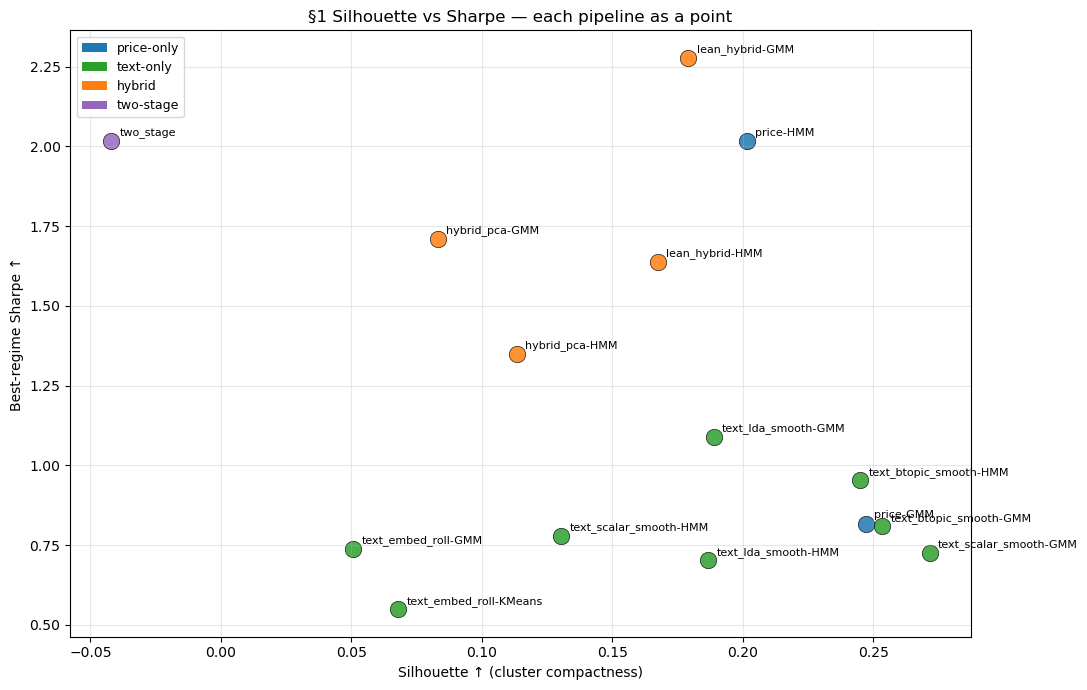

In [6]:
def family_of(name):
    if name.startswith("price"):
        return "price-only"
    if name.startswith("two_stage"):
        return "two-stage"
    if "hybrid" in name or "lean" in name:
        return "hybrid"
    return "text-only"

family_colors = {"price-only": "#1f77b4", "text-only": "#2ca02c",
                 "hybrid":     "#ff7f0e", "two-stage": "#9467bd"}

fig, ax = plt.subplots(figsize=(11, 7))
for name, row in master.iterrows():
    fam = family_of(name)
    ax.scatter(row["Silhouette"], row["Best Sharpe"],
               s=140, color=family_colors[fam], alpha=0.85, edgecolor="black",
               linewidth=0.5)
    ax.annotate(name, (row["Silhouette"], row["Best Sharpe"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Silhouette ↑ (cluster compactness)")
ax.set_ylabel("Best-regime Sharpe ↑")
ax.set_title("§1 Silhouette vs Sharpe — each pipeline as a point")
ax.grid(True, alpha=0.3)
legend_elems = [Patch(facecolor=c, label=f) for f, c in family_colors.items()]
ax.legend(handles=legend_elems, loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/final_sil_sharpe_scatter.png", dpi=120, bbox_inches="tight")
plt.show()


---
## §2. Price-Only Baselines (the baseline to beat)

Two price-only models on `{ret, vol_21, vix, term_spread, credit_spread}`:

- **price-GMM (K=3)** — Gaussian Mixture, full covariance, BIC-selected K.
- **price-HMM (K=5, full)** — Sticky-initialized Gaussian HMM with diagonal=0.85.

These are strong baselines: price-HMM in particular has the highest
rolling-ARI (0.45), one of the best Sharpe (2.02), and long-lived regimes
(mean duration 95 days).


In [7]:
def regime_fin_stats(regime_series, mkt_df, name):
    joined = mkt_df[PRICE_FEATS].join(regime_series.rename("regime"), how="inner").dropna()
    rows = []
    for r, grp in joined.groupby("regime"):
        ann_ret = grp["ret"].mean() * 252
        ann_vol = grp["ret"].std()  * np.sqrt(252)
        sharpe  = ann_ret / ann_vol if ann_vol > 0 else np.nan
        cum     = np.exp(grp["ret"].cumsum())
        dd      = ((cum - cum.cummax()) / cum.cummax()).min()
        rows.append({
            "pipeline":  name,
            "regime":    int(r),
            "n_days":    len(grp),
            "ann_ret":   round(ann_ret, 4),
            "ann_vol":   round(ann_vol, 4),
            "sharpe":    round(sharpe,  3),
            "max_dd":    round(dd,      4),
            "avg_vix":   round(grp["vix"].mean(), 2),
            "avg_vol21": round(grp["vol_21"].mean(), 4),
        })
    return pd.DataFrame(rows)


print("=== price-GMM (K=3, BIC-selected) per-regime stats ===")
display(regime_fin_stats(r_price["gmm_k3"], mkt, "price-GMM").set_index("regime").drop(columns="pipeline"))
print()
print("=== price-HMM (K=5, full cov, sticky init) per-regime stats ===")
display(regime_fin_stats(r_price["hmm_k5_full"], mkt, "price-HMM").set_index("regime").drop(columns="pipeline"))


=== price-GMM (K=3, BIC-selected) per-regime stats ===


,n_days,ann_ret,ann_vol,sharpe,max_dd,avg_vix,avg_vol21
regime,,,,,,,
0,2357,0.0613,0.1371,0.447,-0.3603,18.47,0.1428
1,747,-0.1558,0.4306,-0.362,-0.6405,36.06,0.3534
2,3165,0.1057,0.1295,0.816,-0.3894,17.08,0.1349



=== price-HMM (K=5, full cov, sticky init) per-regime stats ===


,n_days,ann_ret,ann_vol,sharpe,max_dd,avg_vix,avg_vol21
regime,,,,,,,
0,1658,0.1883,0.0934,2.016,-0.0783,13.14,0.0955
1,1655,-0.0350,0.2022,-0.173,-0.4702,22.51,0.1888
2,1407,0.1422,0.1136,1.251,-0.1104,15.67,0.1132
3,438,-0.2199,0.4626,-0.475,-0.5137,40.75,0.4217
4,1111,0.0042,0.1938,0.022,-0.2894,23.03,0.1916


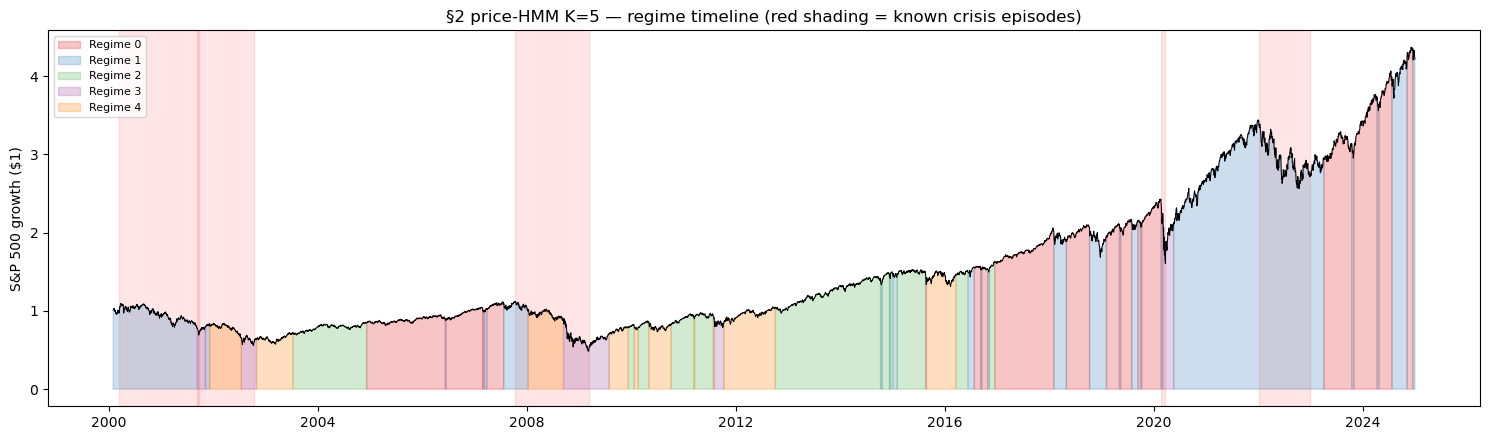

In [8]:
def plot_regime_timeline(dates, returns, labels, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 4))
    cum = np.exp(np.cumsum(returns))
    k = int(labels.max()) + 1
    ax.plot(dates, cum, linewidth=0.7, color="black")
    for r in range(k):
        mask = labels == r
        ax.fill_between(dates, 0, cum, where=mask, alpha=0.25,
                        color=COLORS[r % len(COLORS)], label=f"Regime {r}")
    for (_ep_name, ep_start, ep_end) in EPISODES:
        ax.axvspan(pd.Timestamp(ep_start), pd.Timestamp(ep_end),
                   alpha=0.10, color="red", zorder=0)
    ax.set_title(title)
    ax.set_ylabel("S&P 500 growth ($1)")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    return ax


joined = mkt[["ret"]].join(r_price["hmm_k5_full"].rename("regime"), how="inner").dropna()
fig, ax = plt.subplots(figsize=(15, 4.5))
plot_regime_timeline(joined.index, joined["ret"].values,
                     joined["regime"].values.astype(int),
                     "§2 price-HMM K=5 — regime timeline (red shading = known crisis episodes)",
                     ax=ax)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/final_regime_timeline.png", dpi=120, bbox_inches="tight")
plt.show()


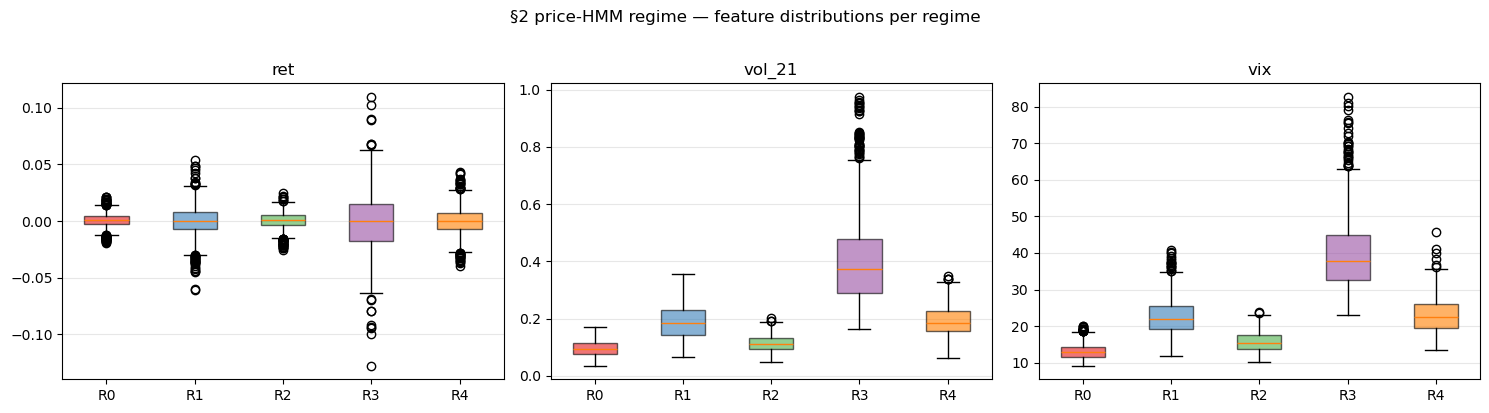

In [9]:
joined = mkt[PRICE_FEATS].join(r_price["hmm_k5_full"].rename("regime"), how="inner").dropna()
features_to_plot = ["ret", "vol_21", "vix"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, features_to_plot):
    regimes_present = sorted(joined["regime"].unique())
    data_by_reg = [joined[joined["regime"] == r][feat].values for r in regimes_present]
    bp = ax.boxplot(data_by_reg, patch_artist=True,
                    labels=[f"R{r}" for r in regimes_present])
    for patch, color in zip(bp["boxes"], COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.set_title(feat)
    ax.grid(True, alpha=0.3, axis="y")
plt.suptitle("§2 price-HMM regime — feature distributions per regime", y=1.02)
plt.tight_layout()
plt.show()


---
## §3. Text Representations — 4-way Ablation

Four ways to represent daily headline text as features for a regime model:

| Representation | Dim | Source |
|---|---|---|
| **Scalar sentiment** | 5 | RavenPack CSS aggregates (mean/std/count + ESS + sent_net) |
| **LDA topics** | 15 | LDA(K=15) fit on 300k sampled headlines, mean-pooled daily |
| **FinBERT raw** | 768 → PCA(20) | `ProsusAI/finbert` CLS embedding, daily mean, then PCA(20) |
| **BERTopic vectors** | ~14 | BERTopic probability vector per day (21d rolling) |

The hypothesis tested by §3 is whether the choice of text representation
explains the v1 weakness of `text_embed_roll-*` (silhouette ≈ 0.05).


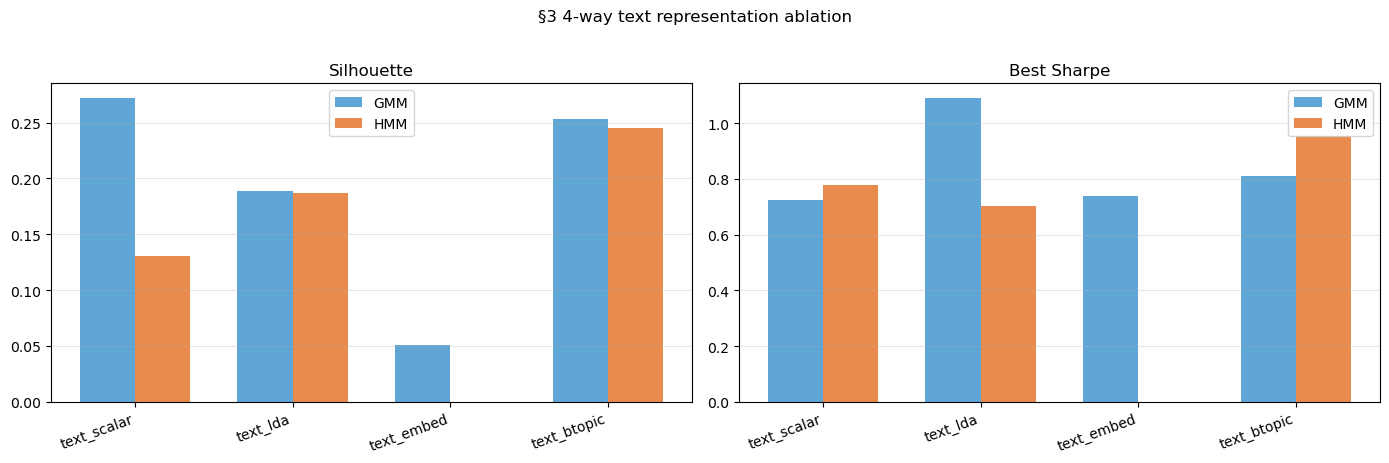

In [10]:
reps = ["text_scalar_smooth", "text_lda_smooth", "text_embed_roll", "text_btopic_smooth"]
metrics = ["Silhouette", "Best Sharpe"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, met in zip(axes, metrics):
    gmm_vals = [master.loc[f"{r}-GMM", met] if f"{r}-GMM" in master.index else np.nan for r in reps]
    hmm_vals = [master.loc[f"{r}-HMM", met] if f"{r}-HMM" in master.index else np.nan for r in reps]
    x = np.arange(len(reps)); w = 0.35
    ax.bar(x - w/2, gmm_vals, w, label="GMM",      color="#5fa5d6")
    ax.bar(x + w/2, hmm_vals, w, label="HMM",      color="#e88b4d")
    ax.set_xticks(x)
    ax.set_xticklabels([r.replace("_smooth", "").replace("_roll", "") for r in reps],
                       rotation=20, ha="right")
    ax.set_title(met)
    ax.grid(True, alpha=0.3, axis="y")
    ax.legend()
plt.suptitle("§3 4-way text representation ablation", y=1.02)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/final_text_ablation_bars.png", dpi=120, bbox_inches="tight")
plt.show()


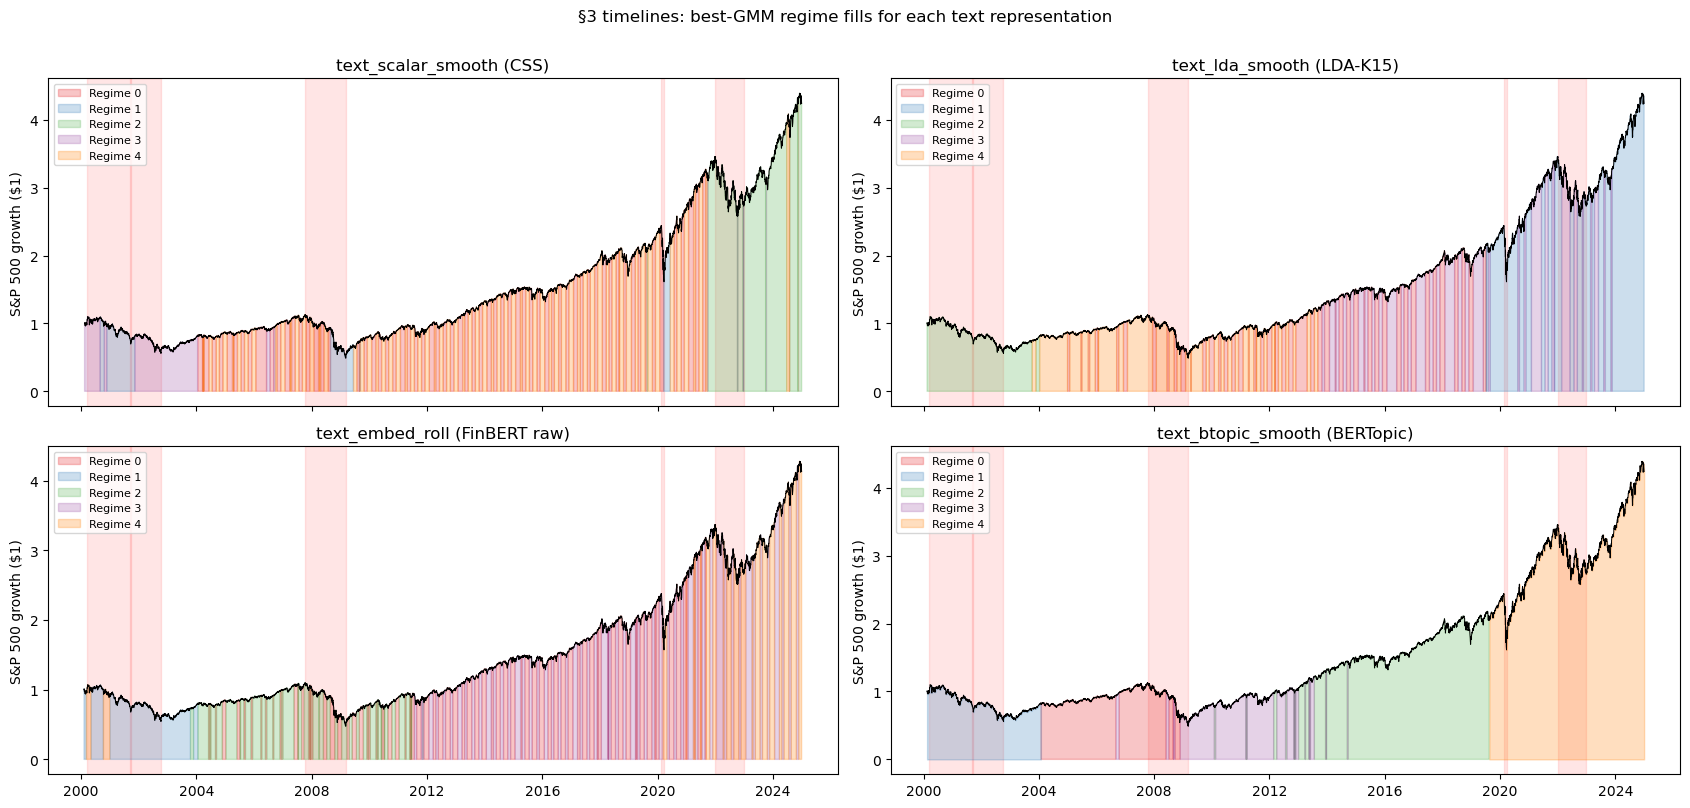

In [11]:
# 2x2 grid of timelines, one per representation (using each's best GMM variant)
best_per_rep = {
    "text_scalar_smooth (CSS)":      r_ts["gmm"],
    "text_lda_smooth (LDA-K15)":     r_lda["gmm"],
    "text_embed_roll (FinBERT raw)": r_emb["gmm"],
    "text_btopic_smooth (BERTopic)": r_btopic["gmm"],
}

fig, axes = plt.subplots(2, 2, figsize=(17, 8), sharex=True)
for ax, (label, series) in zip(axes.flatten(), best_per_rep.items()):
    joined = mkt[["ret"]].join(series.rename("regime"), how="inner").dropna()
    plot_regime_timeline(joined.index, joined["ret"].values,
                         joined["regime"].values.astype(int), label, ax=ax)
plt.suptitle("§3 timelines: best-GMM regime fills for each text representation",
             y=1.005)
plt.tight_layout()
plt.show()


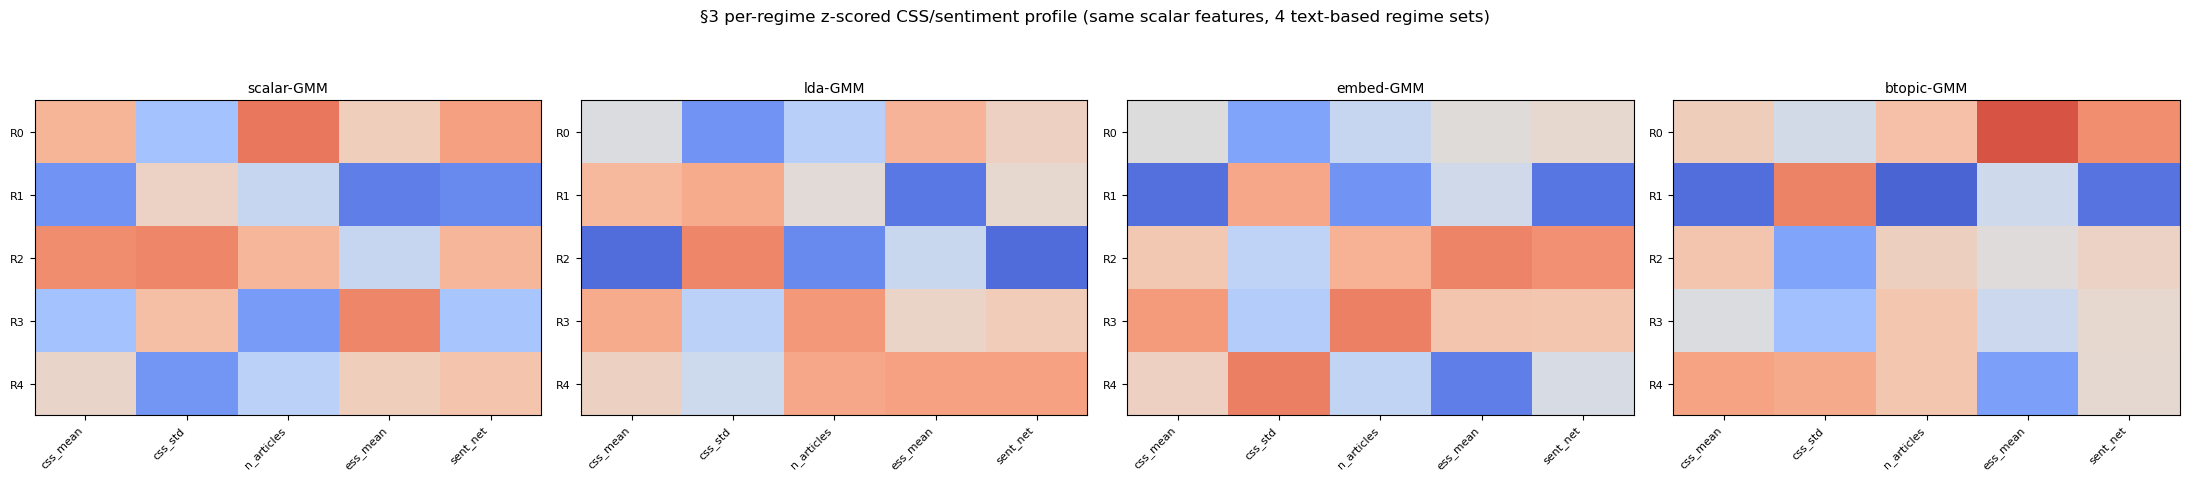

In [12]:
# Per-regime CSS/sentiment profile under each text representation.
# Always use the smoothed scalar features as the profile basis so the 4
# panels are comparable.
def regime_text_profile(regime_series, news_smoothed):
    df = news_smoothed.join(regime_series.rename("regime"), how="inner").dropna()
    return df.groupby("regime").mean()

profiles = {
    "scalar-GMM": regime_text_profile(r_ts["gmm"],     news_smooth),
    "lda-GMM":    regime_text_profile(r_lda["gmm"],    news_smooth),
    "embed-GMM":  regime_text_profile(r_emb["gmm"],    news_smooth),
    "btopic-GMM": regime_text_profile(r_btopic["gmm"], news_smooth),
}

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (name, prof) in zip(axes, profiles.items()):
    z = (prof - prof.mean()) / (prof.std() + 1e-9)
    im = ax.imshow(z.values, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
    ax.set_xticks(range(len(prof.columns)))
    ax.set_xticklabels(prof.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(prof)))
    ax.set_yticklabels([f"R{r}" for r in prof.index], fontsize=8)
    ax.set_title(name, fontsize=10)
plt.suptitle("§3 per-regime z-scored CSS/sentiment profile (same scalar features, 4 text-based regime sets)",
             y=1.06)
plt.tight_layout()
plt.show()


### Key finding — §3

**BERTopic vectors are the clear winner among text-only representations,
and FinBERT raw mean-pooling is the weakest.**

| Representation | Silhouette (GMM) | Silhouette (HMM) | Best Sharpe |
|---|---|---|---|
| text_scalar_smooth | **0.272** | 0.130 | 0.725 (GMM) |
| text_lda_smooth    | 0.189     | 0.187 | 1.089 (GMM) |
| text_embed_roll (FinBERT raw) | 0.051 | — | 0.739 (GMM) |
| **text_btopic_smooth** | **0.254** | **0.245** | 0.953 (HMM) |

Why FinBERT raw fails and BERTopic succeeds:

- FinBERT CLS is a 768-d dense embedding optimized for fine-grained sentence
  sentiment polarity. Mean-pooling 30–50 headlines per day averages out most
  regime-discriminative variance; PCA(20) afterward mixes residual signal
  with noise PCs.
- BERTopic produces a ~14-d probability vector over discrete topic clusters
  chosen to maximize inter-topic separation. The simplex constraint and lower
  dimensionality both reduce the over-smoothing problem.

`text_scalar_smooth-GMM` ties BERTopic on silhouette — the simplest possible
representation (5 hand-engineered scalars) already captures the dominant
signal. Adding sophistication via FinBERT does not help; **representation
choice matters more than representation capacity**.


In [13]:
# ARI between the two "embedding-style" text representations and the scalar baseline
def ari_between(a_series, b_series):
    common = a_series.to_frame("x").join(b_series.rename("y"), how="inner").dropna()
    return adjusted_rand_score(common["x"].astype(int), common["y"].astype(int))

print(f"ARI(btopic-GMM, embed-GMM):  {ari_between(r_btopic['gmm'], r_emb['gmm']):.4f}")
print(f"ARI(btopic-GMM, scalar-GMM): {ari_between(r_btopic['gmm'], r_ts['gmm']):.4f}")
print(f"ARI(embed-GMM,  scalar-GMM): {ari_between(r_emb['gmm'],    r_ts['gmm']):.4f}")
print()
print("Reading: ARI=1 means identical labelings; ARI=0 means independent.")
print("Despite both being 'text-embedding' style pipelines, btopic and FinBERT-raw")
print("produce nearly unrelated regime assignments — the two embeddings emphasize")
print("very different headline-level features.")


ARI(btopic-GMM, embed-GMM):  0.3468
ARI(btopic-GMM, scalar-GMM): 0.2411
ARI(embed-GMM,  scalar-GMM): 0.3449

Reading: ARI=1 means identical labelings; ARI=0 means independent.
Despite both being 'text-embedding' style pipelines, btopic and FinBERT-raw
produce nearly unrelated regime assignments — the two embeddings emphasize
very different headline-level features.


---
## §4. Hybrid Fusion — Design Matters

Two hybrid designs evaluated on the same {price + text-scalar} feature
universe:

- **`hybrid_pca` (v1):** Standardize price and text separately, run PCA(95%)
  on each side, re-standardize the PCs, concatenate. Silhouette 0.08,
  Best Sharpe 1.71.
- **`lean_hybrid` (new):** Select 3 features per side
  `{ret, vol_21, vix} + {css_mean, sent_net, n_articles}`, standardize, no
  PCA. Silhouette 0.18, Best Sharpe **2.28** (best across all pipelines).


In [14]:
hybrid_rows = master.loc[[
    "price-GMM",              "price-HMM",
    "text_scalar_smooth-GMM", "text_scalar_smooth-HMM",
    "hybrid_pca-GMM",         "hybrid_pca-HMM",
    "lean_hybrid-GMM",        "lean_hybrid-HMM",
]].copy()
print("§4 hybrid comparison — individual modalities vs two hybrid designs:")
display(hybrid_rows.style.format("{:.3f}"))


§4 hybrid comparison — individual modalities vs two hybrid designs:


,Silhouette,DBI,Mean Dur (d),Rolling ARI,Best Sharpe
pipeline,,,,,
price-GMM,0.247,1.399,17.500,0.369,0.816
price-HMM,0.202,1.480,95.000,0.447,2.016
text_scalar_smooth-GMM,0.272,1.288,36.600,0.414,0.725
text_scalar_smooth-HMM,0.130,2.085,118.100,0.222,0.778
hybrid_pca-GMM,0.083,2.111,24.600,0.273,1.709
hybrid_pca-HMM,0.114,2.033,142.300,0.251,1.349
lean_hybrid-GMM,0.179,1.558,11.400,0.407,2.277
lean_hybrid-HMM,0.168,1.702,31.300,0.407,1.638


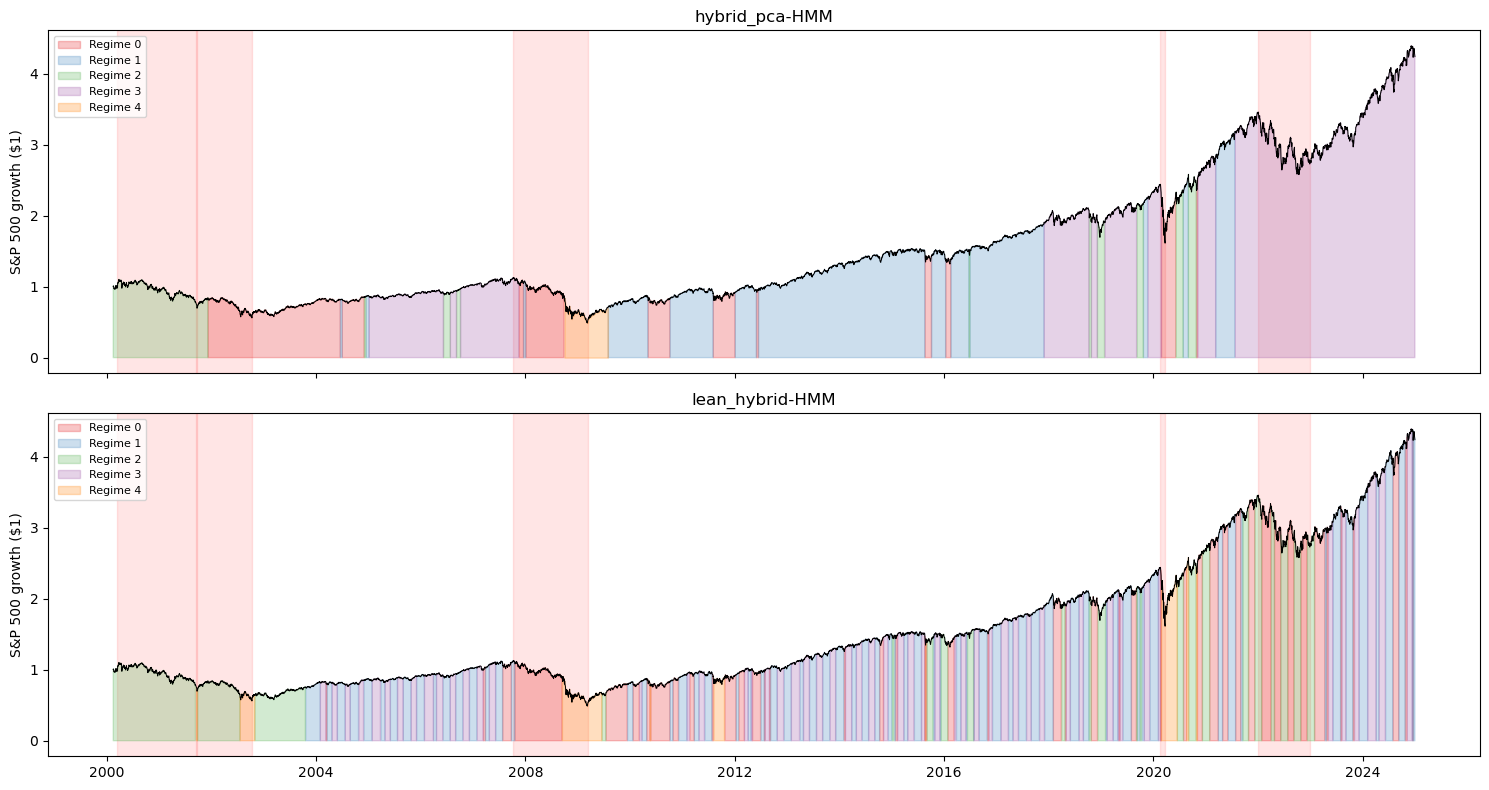

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, (name, series) in zip(axes, [
    ("hybrid_pca-HMM",  r_hyb["hmm"]),
    ("lean_hybrid-HMM", r_lean["hmm"]),
]):
    joined = mkt[["ret"]].join(series.rename("regime"), how="inner").dropna()
    plot_regime_timeline(joined.index, joined["ret"].values,
                         joined["regime"].values.astype(int), name, ax=ax)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/final_hybrid_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


In [16]:
def per_regime_breakdown(regime_series, name):
    df = mkt[["ret"]].join(regime_series.rename("regime"), how="inner").dropna()
    labels = df["regime"].values.astype(int)
    rows = []
    for r in sorted(df["regime"].unique()):
        grp = df[df["regime"] == r]
        ann_ret = grp["ret"].mean() * 252
        ann_vol = grp["ret"].std()  * np.sqrt(252)
        sharpe  = ann_ret / ann_vol if ann_vol > 0 else np.nan
        # Run-length: count consecutive runs of regime r
        run_lens, cnt, in_run = [], 0, False
        for v in labels:
            if v == r:
                cnt += 1; in_run = True
            else:
                if in_run:
                    run_lens.append(cnt)
                cnt, in_run = 0, False
        if in_run:
            run_lens.append(cnt)
        mean_run = float(np.mean(run_lens)) if run_lens else 0.0
        rows.append({
            "pipeline": name, "regime": int(r), "n_days": len(grp),
            "sharpe":  round(sharpe,  3),
            "ann_ret": round(ann_ret, 4),
            "ann_vol": round(ann_vol, 4),
            "mean_run_days": round(mean_run, 1),
            "n_runs": len(run_lens),
        })
    return pd.DataFrame(rows)


print("=== lean_hybrid-GMM per-regime breakdown ===")
display(per_regime_breakdown(r_lean["gmm"], "lean_hybrid-GMM"))
print()
print("=== hybrid_pca-HMM per-regime breakdown ===")
display(per_regime_breakdown(r_hyb["hmm"], "hybrid_pca-HMM"))


=== lean_hybrid-GMM per-regime breakdown ===


,pipeline,regime,n_days,sharpe,ann_ret,ann_vol,mean_run_days,n_runs
0,lean_hybrid-GMM,0,1886,2.277,0.2145,0.0942,12.3,153
1,lean_hybrid-GMM,1,1347,-0.289,-0.0566,0.1959,15.1,89
2,lean_hybrid-GMM,2,1397,-0.189,-0.0433,0.2293,8.2,170
3,lean_hybrid-GMM,3,1362,2.052,0.1791,0.0873,11.9,114
4,lean_hybrid-GMM,4,268,-0.991,-0.5507,0.5559,12.8,21



=== hybrid_pca-HMM per-regime breakdown ===


,pipeline,regime,n_days,sharpe,ann_ret,ann_vol,mean_run_days,n_runs
0,hybrid_pca-HMM,0,1301,-0.087,-0.0221,0.2558,118.3,11
1,hybrid_pca-HMM,1,1995,1.349,0.1572,0.1166,153.5,13
2,hybrid_pca-HMM,2,672,-0.403,-0.0862,0.2138,67.2,10
3,hybrid_pca-HMM,3,2082,0.628,0.0923,0.1469,231.3,9
4,hybrid_pca-HMM,4,210,-0.549,-0.2619,0.4768,210.0,1


### Key finding — §4

**`lean_hybrid` wins Sharpe at the cost of compactness; `hybrid_pca` PCA-fusion
underperforms both single-modality baselines.**

- `lean_hybrid-GMM` achieves the highest best-regime Sharpe (**2.28**) in
  the entire study. But silhouette is moderate (0.18) and the best-Sharpe
  regime is short-lived: mean run length ~11 days. Interpretation: the model
  identifies a small, transient "calm rally" pocket with excellent
  risk-adjusted returns. This is a real signal but not a long-lived regime.
- `hybrid_pca-GMM` produces silhouette **0.08** — lower than both `price-GMM`
  (0.25) and `text_scalar_smooth-GMM` (0.27). PCA on each side projects the
  regime-discriminative directions into low-variance PCs that get truncated
  or down-weighted. Concatenating PCs from two different feature geometries
  also distorts the joint distribution.
- Practical implication: **simple feature selection beats automatic feature
  compression** when feature counts are small (here ≤ 10) and the
  signal-to-noise ratio on each feature is well understood.


---
## §5. Cross-Pipeline Robustness

When 14+ pipelines all claim to find market regimes, do they agree? This
section measures pairwise consistency (ARI), temporal stability (mean
duration vs rolling ARI), crisis-period alignment, and annual regime share.


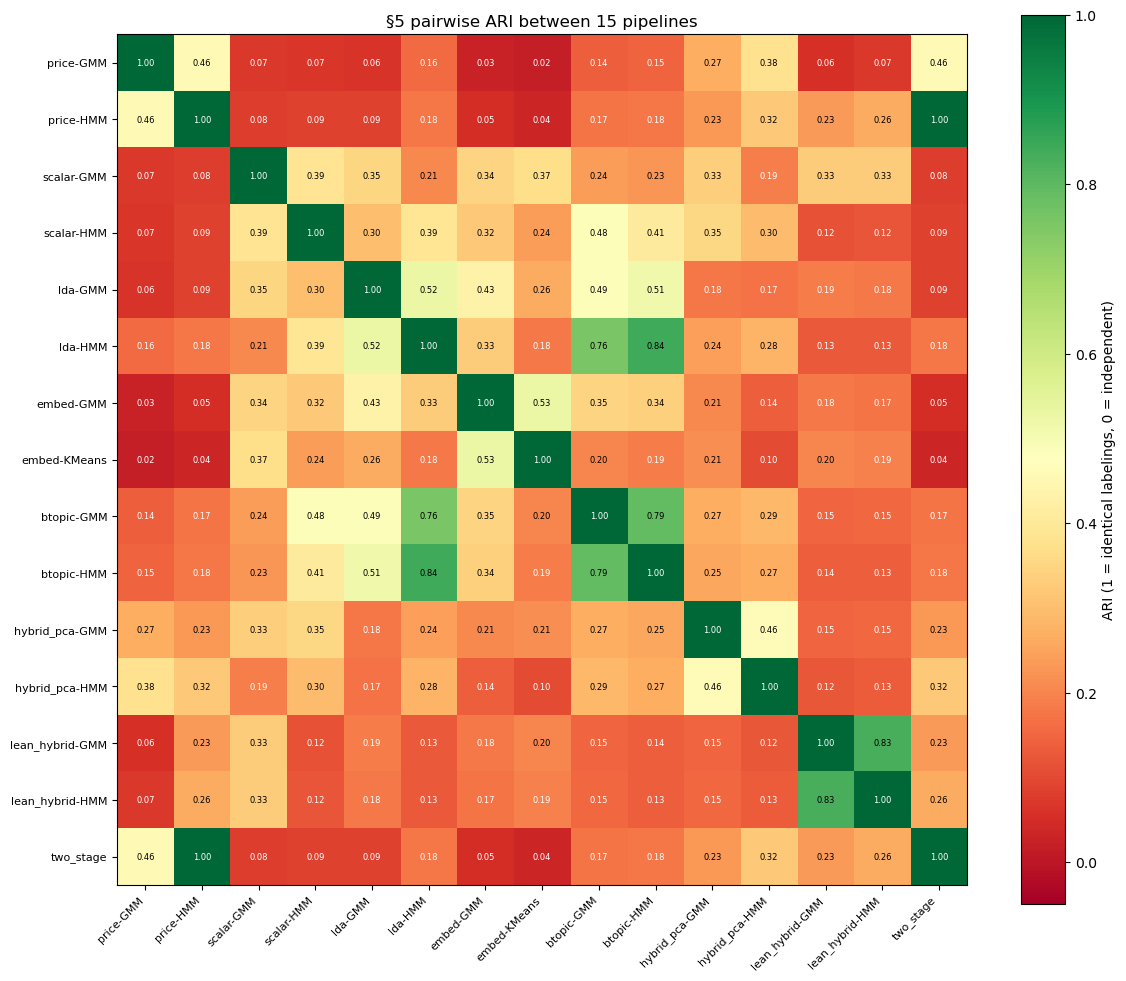


Top 5 most similar pipeline pairs:
  ARI=1.000   price-HMM   <->   two_stage
  ARI=0.841   lda-HMM   <->   btopic-HMM
  ARI=0.829   lean_hybrid-GMM   <->   lean_hybrid-HMM
  ARI=0.795   btopic-GMM   <->   btopic-HMM
  ARI=0.756   lda-HMM   <->   btopic-GMM

Bottom 5 most dissimilar pipeline pairs:
  ARI=0.050   embed-GMM   <->   two_stage
  ARI=0.035   price-HMM   <->   embed-KMeans
  ARI=0.035   embed-KMeans   <->   two_stage
  ARI=0.025   price-GMM   <->   embed-GMM
  ARI=0.017   price-GMM   <->   embed-KMeans


In [17]:
all_regimes = {
    "price-GMM":       r_price["gmm_k3"],
    "price-HMM":       r_price["hmm_k5_full"],
    "scalar-GMM":      r_ts["gmm"],
    "scalar-HMM":      r_ts["hmm"],
    "lda-GMM":         r_lda["gmm"],
    "lda-HMM":         r_lda["hmm"],
    "embed-GMM":       r_emb["gmm"],
    "embed-KMeans":    r_emb["kmeans"],
    "btopic-GMM":      r_btopic["gmm"],
    "btopic-HMM":      r_btopic["hmm"],
    "hybrid_pca-GMM":  r_hyb["gmm"],
    "hybrid_pca-HMM":  r_hyb["hmm"],
    "lean_hybrid-GMM": r_lean["gmm"],
    "lean_hybrid-HMM": r_lean["hmm"],
    "two_stage":       r_2stage["hmm"],
}
names = list(all_regimes.keys())
n = len(names)
M = np.full((n, n), np.nan)
for i, a in enumerate(names):
    M[i, i] = 1.0
    for j in range(i + 1, n):
        b = names[j]
        common = all_regimes[a].to_frame("x").join(
            all_regimes[b].rename("y"), how="inner").dropna()
        if len(common) >= 100:
            v = adjusted_rand_score(common["x"].astype(int), common["y"].astype(int))
            M[i, j] = v
            M[j, i] = v

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(M, cmap="RdYlGn", vmin=-0.05, vmax=1.0)
ax.set_xticks(range(n)); ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(n)); ax.set_yticklabels(names, fontsize=8)
for i in range(n):
    for j in range(n):
        v = M[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                    color="black" if 0.2 < v < 0.85 else "white")
plt.colorbar(im, ax=ax, label="ARI (1 = identical labelings, 0 = independent)")
ax.set_title(f"§5 pairwise ARI between {n} pipelines")
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/final_pairwise_ari.png", dpi=120, bbox_inches="tight")
plt.show()

pairs = []
for i in range(n):
    for j in range(i + 1, n):
        if not np.isnan(M[i, j]):
            pairs.append((M[i, j], names[i], names[j]))
pairs.sort(reverse=True)
print()
print("Top 5 most similar pipeline pairs:")
for v, a, b in pairs[:5]:
    print(f"  ARI={v:.3f}   {a}   <->   {b}")
print()
print("Bottom 5 most dissimilar pipeline pairs:")
for v, a, b in pairs[-5:]:
    print(f"  ARI={v:.3f}   {a}   <->   {b}")


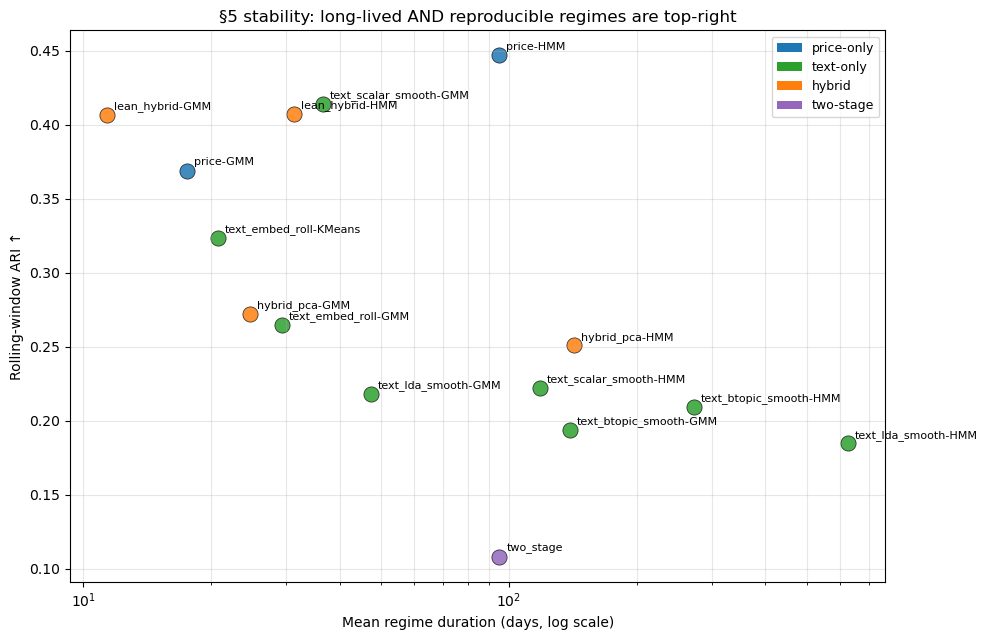

In [18]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for name, row in master.iterrows():
    fam = family_of(name)
    ax.scatter(row["Mean Dur (d)"], row["Rolling ARI"],
               s=120, color=family_colors[fam], alpha=0.85, edgecolor="black",
               linewidth=0.5)
    ax.annotate(name, (row["Mean Dur (d)"], row["Rolling ARI"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Mean regime duration (days, log scale)")
ax.set_ylabel("Rolling-window ARI ↑")
ax.set_title("§5 stability: long-lived AND reproducible regimes are top-right")
ax.grid(True, alpha=0.3, which="both")
legend_elems = [Patch(facecolor=c, label=f) for f, c in family_colors.items()]
ax.legend(handles=legend_elems, loc="best", fontsize=9)
plt.tight_layout()
plt.show()


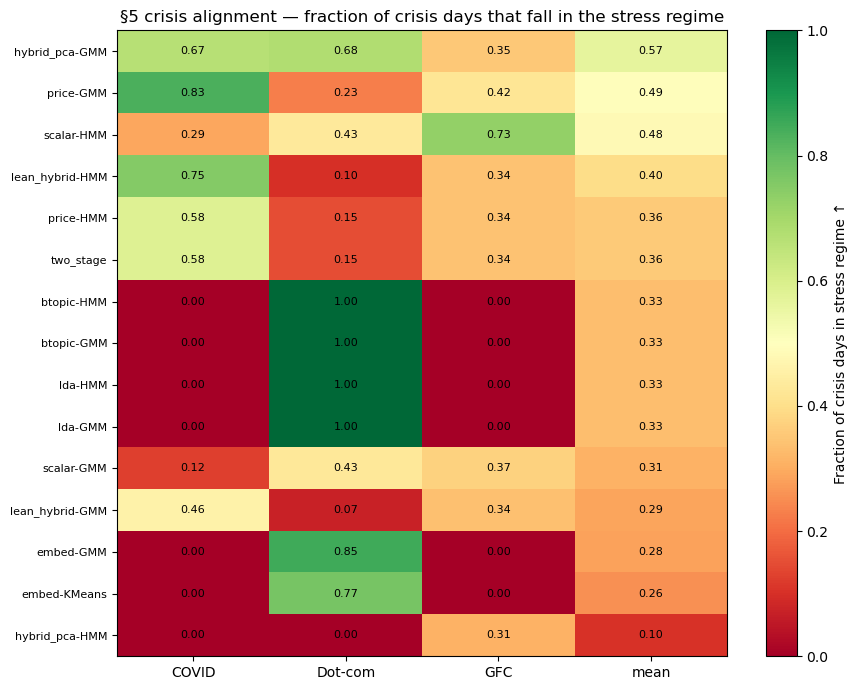

In [19]:
crisis_windows = {
    "Dot-com": ("2000-03-10", "2002-10-09"),
    "GFC":     ("2007-10-09", "2009-03-09"),
    "COVID":   ("2020-02-19", "2020-03-23"),
}
rows = []
for name, series in all_regimes.items():
    joined = mkt[["ret"]].join(series.rename("regime"), how="inner").dropna()
    reg_ret = joined.groupby("regime")["ret"].mean() * 252
    stress_r = int(reg_ret.idxmin())
    for c_name, (s, e) in crisis_windows.items():
        m = (joined.index >= s) & (joined.index <= e)
        cdays = joined.loc[m]
        frac = float((cdays["regime"] == stress_r).mean()) if len(cdays) else np.nan
        rows.append({"pipeline": name, "crisis": c_name,
                     "frac_in_stress": round(frac, 3) if pd.notna(frac) else np.nan})

df_c = pd.DataFrame(rows).pivot(index="pipeline", columns="crisis", values="frac_in_stress")
df_c["mean"] = df_c.mean(axis=1)
df_c = df_c.sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(df_c.values.astype(float), aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(df_c.columns))); ax.set_xticklabels(df_c.columns, fontsize=10)
ax.set_yticks(range(len(df_c)));         ax.set_yticklabels(df_c.index, fontsize=8)
for i in range(len(df_c)):
    for j in range(len(df_c.columns)):
        v = df_c.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="Fraction of crisis days in stress regime ↑")
ax.set_title("§5 crisis alignment — fraction of crisis days that fall in the stress regime")
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/final_crisis_alignment.png", dpi=120, bbox_inches="tight")
plt.show()


Top-3 by silhouette: ['text_scalar_smooth-GMM', 'text_btopic_smooth-GMM', 'price-GMM']


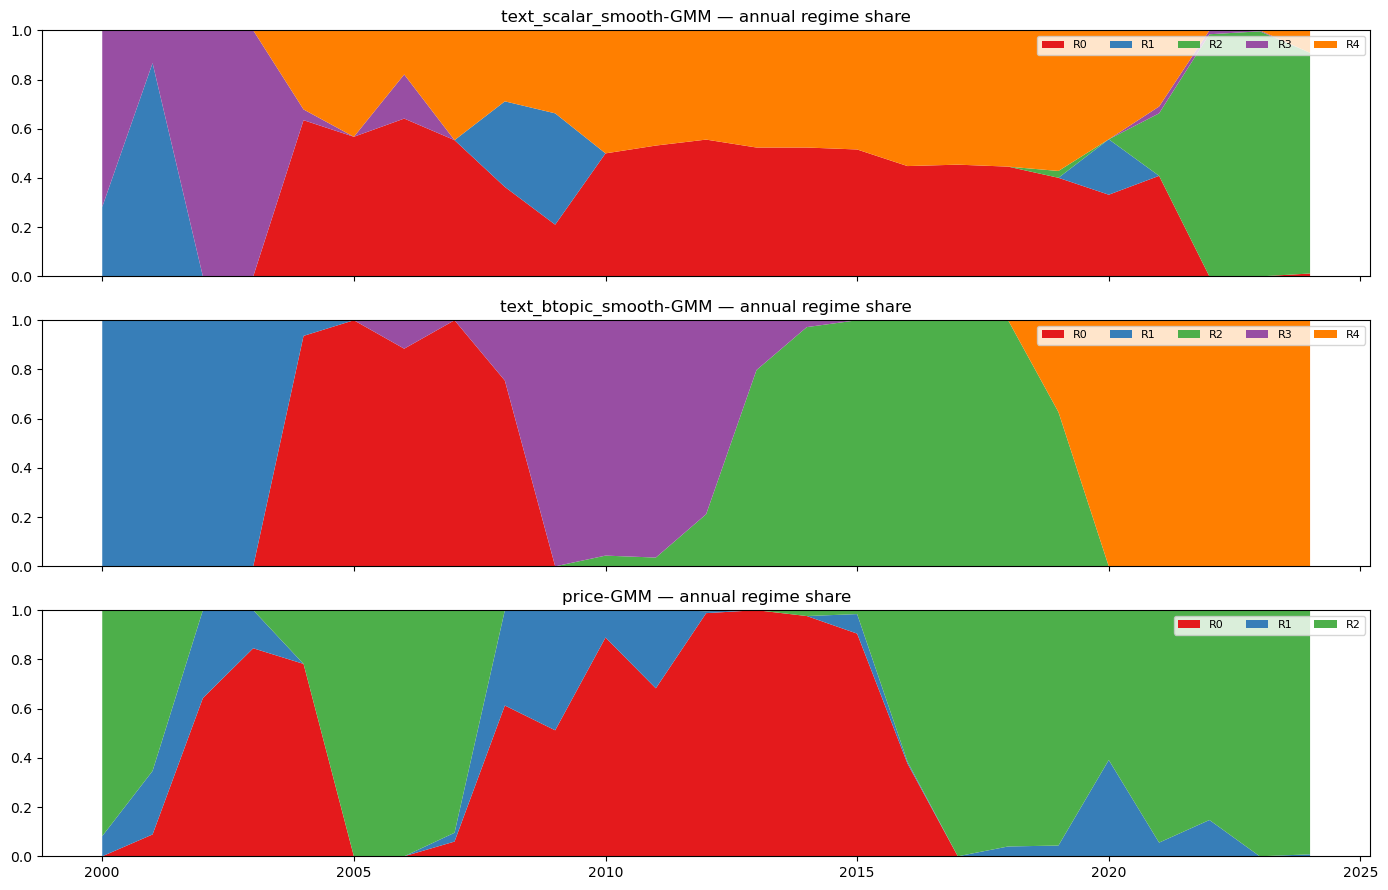

In [20]:
# Annual regime share (stacked area) for the top-3 pipelines by silhouette
name_to_series = {
    "price-GMM": r_price["gmm_k3"], "price-HMM": r_price["hmm_k5_full"],
    "text_scalar_smooth-GMM": r_ts["gmm"], "text_scalar_smooth-HMM": r_ts["hmm"],
    "text_lda_smooth-GMM": r_lda["gmm"], "text_lda_smooth-HMM": r_lda["hmm"],
    "text_embed_roll-GMM": r_emb["gmm"], "text_embed_roll-KMeans": r_emb["kmeans"],
    "text_btopic_smooth-GMM": r_btopic["gmm"], "text_btopic_smooth-HMM": r_btopic["hmm"],
    "hybrid_pca-GMM": r_hyb["gmm"], "hybrid_pca-HMM": r_hyb["hmm"],
    "lean_hybrid-GMM": r_lean["gmm"], "lean_hybrid-HMM": r_lean["hmm"],
    "two_stage": r_2stage["hmm"],
}

top3 = master_by_sil.head(3).index.tolist()
print(f"Top-3 by silhouette: {top3}")

fig, axes = plt.subplots(len(top3), 1, figsize=(14, 9), sharex=True)
for ax, pname in zip(axes, top3):
    s = name_to_series[pname].dropna().astype(int)
    df = s.to_frame("regime")
    df["year"] = df.index.year
    pivot = df.groupby(["year", "regime"]).size().unstack(fill_value=0)
    pivot_pct = pivot.div(pivot.sum(axis=1), axis=0)
    ax.stackplot(pivot_pct.index, pivot_pct.values.T,
                 labels=[f"R{r}" for r in pivot_pct.columns],
                 colors=COLORS[:pivot_pct.shape[1]])
    ax.set_title(f"{pname} — annual regime share")
    ax.set_ylim(0, 1)
    ax.legend(loc="upper right", fontsize=8, ncol=pivot_pct.shape[1])
plt.tight_layout()
plt.show()


---
## §6. Two-Stage Regime Characterization

The two-stage approach uses **price-HMM (K=5, full cov)** labels — the most
stable price-based regime structure — and characterizes each regime through
its average LDA / BERTopic / sentiment profile. This avoids the
silhouette-negative trap of clustering directly in text feature space
(cf. `two_stage` row in master, silhouette − 0.04), while still delivering
the interpretive payoff the proposal called for.


In [21]:
two_stage = r_2stage["hmm"]
K = int(two_stage.max()) + 1
joined = mkt.join(news_raw[["css_mean", "n_articles"]], how="left")\
            .join(two_stage.rename("regime"), how="inner")\
            .dropna(subset=["regime"])

rows = []
for r, grp in joined.groupby("regime"):
    ann_ret = grp["ret"].mean() * 252
    ann_vol = grp["ret"].std()  * np.sqrt(252)
    sharpe  = ann_ret / ann_vol if ann_vol > 0 else np.nan
    cum     = np.exp(grp["ret"].cumsum())
    dd      = ((cum - cum.cummax()) / cum.cummax()).min()
    rows.append({
        "regime":         int(r),
        "n_days":         len(grp),
        "date_from":      grp.index.min().date(),
        "date_to":        grp.index.max().date(),
        "ann_ret":        round(ann_ret, 4),
        "ann_vol":        round(ann_vol, 4),
        "sharpe":         round(sharpe, 3),
        "max_dd":         round(dd, 4),
        "avg_vix":        round(grp["vix"].mean(), 2),
        "avg_n_articles": int(round(grp["n_articles"].mean())),
        "avg_css":        round(grp["css_mean"].mean(), 4),
    })
stats_2s = pd.DataFrame(rows).set_index("regime")
print("§6 two-stage per-regime market + news stats:")
display(stats_2s)


§6 two-stage per-regime market + news stats:


,n_days,date_from,date_to,ann_ret,ann_vol,sharpe,max_dd,avg_vix,avg_n_articles,avg_css
regime,,,,,,,,,,
0,1658,2004-12-08,2024-12-16,0.1883,0.0934,2.016,-0.0783,13.14,6139,0.0116
1,1655,2000-02-01,2024-12-31,-0.0350,0.2022,-0.173,-0.4702,22.51,5380,0.0071
2,1407,2003-07-11,2016-12-15,0.1422,0.1136,1.251,-0.1104,15.67,6384,0.0092
3,438,2001-09-17,2020-05-19,-0.2199,0.4626,-0.475,-0.5137,40.75,5725,-0.0026
4,1111,2001-12-07,2016-03-18,0.0042,0.1938,0.022,-0.2894,23.03,5704,0.0044


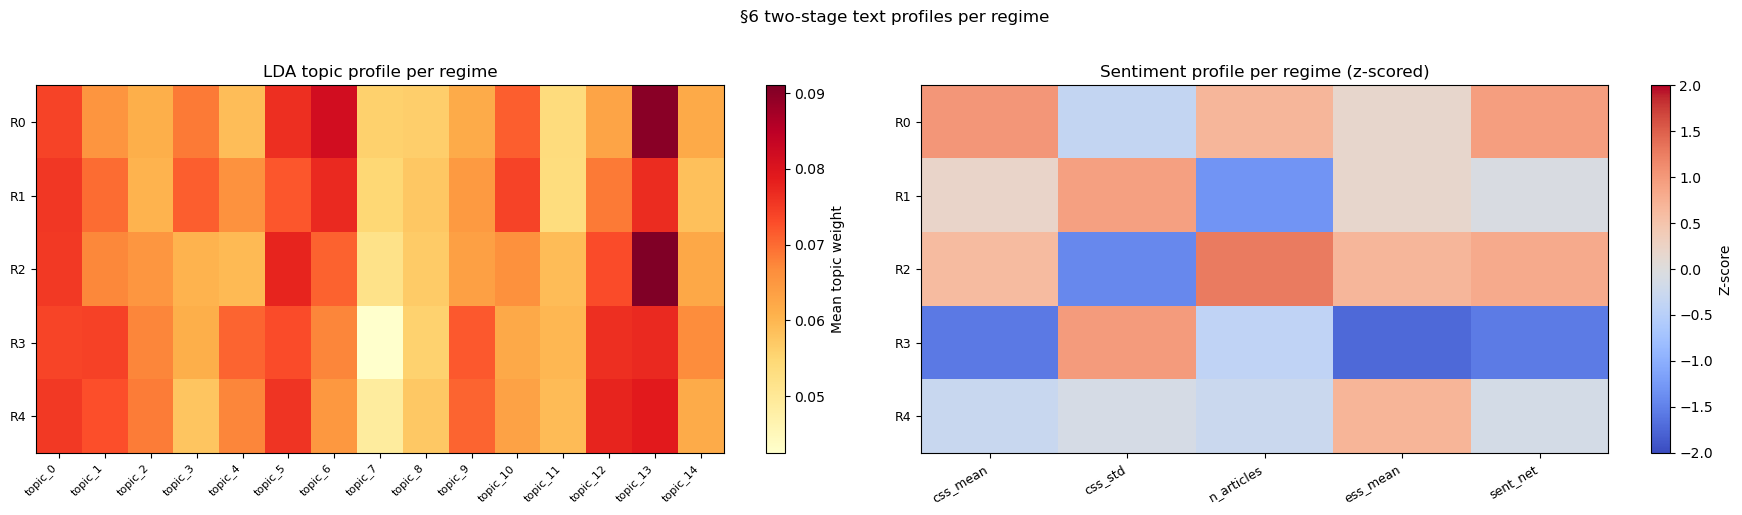

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
im0 = axes[0].imshow(lda_profile.values, aspect="auto", cmap="YlOrRd")
axes[0].set_xticks(range(len(lda_profile.columns)))
axes[0].set_xticklabels(lda_profile.columns, rotation=45, ha="right", fontsize=8)
axes[0].set_yticks(range(K))
axes[0].set_yticklabels([f"R{r}" for r in lda_profile.index], fontsize=9)
plt.colorbar(im0, ax=axes[0], label="Mean topic weight")
axes[0].set_title("LDA topic profile per regime")

z = (news_profile - news_profile.mean()) / (news_profile.std() + 1e-9)
im1 = axes[1].imshow(z.values, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
axes[1].set_xticks(range(len(news_profile.columns)))
axes[1].set_xticklabels(news_profile.columns, rotation=30, ha="right", fontsize=9)
axes[1].set_yticks(range(K))
axes[1].set_yticklabels([f"R{r}" for r in news_profile.index], fontsize=9)
plt.colorbar(im1, ax=axes[1], label="Z-score")
axes[1].set_title("Sentiment profile per regime (z-scored)")

plt.suptitle("§6 two-stage text profiles per regime", y=1.02)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/final_twostage_profiles.png", dpi=120, bbox_inches="tight")
plt.show()


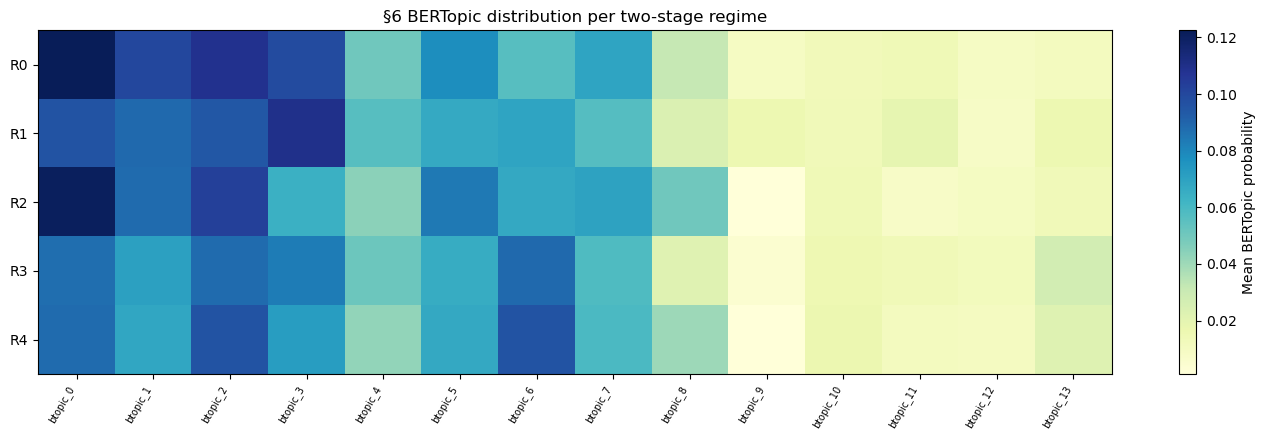

In [23]:
bert_with = bert_smooth.join(two_stage.rename("regime"), how="inner").dropna(subset=["regime"])
bert_profile = bert_with.groupby("regime")[bert_smooth.columns.tolist()].mean()

fig, ax = plt.subplots(figsize=(14, 4.5))
im = ax.imshow(bert_profile.values, aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(len(bert_profile.columns)))
ax.set_xticklabels(bert_profile.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(K))
ax.set_yticklabels([f"R{r}" for r in bert_profile.index])
plt.colorbar(im, ax=ax, label="Mean BERTopic probability")
ax.set_title("§6 BERTopic distribution per two-stage regime")
plt.tight_layout()
plt.show()


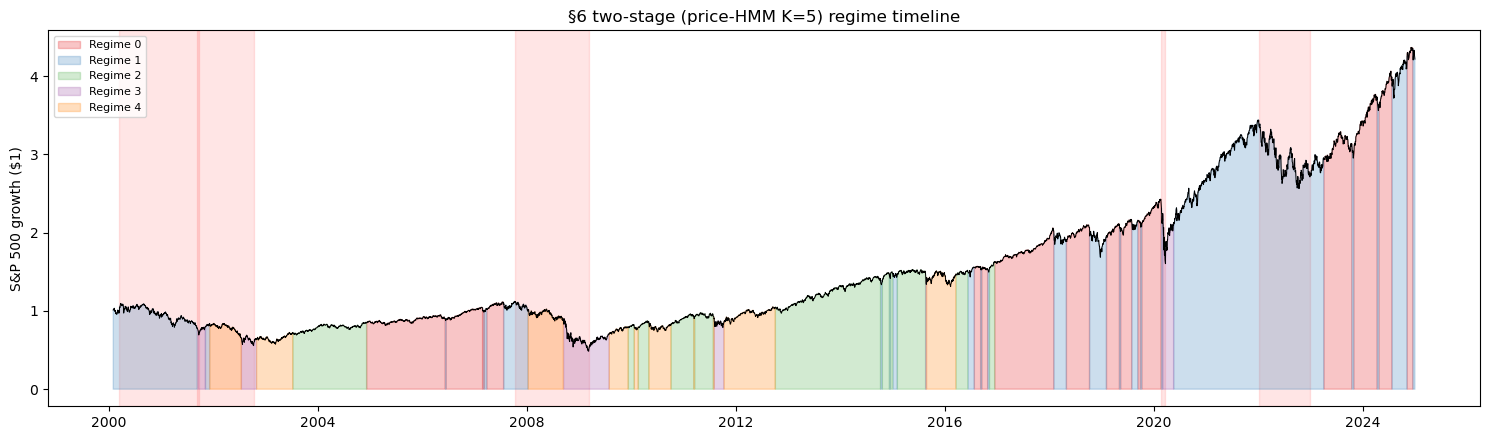

In [24]:
joined = mkt[["ret"]].join(two_stage.rename("regime"), how="inner").dropna()
fig, ax = plt.subplots(figsize=(15, 4.5))
plot_regime_timeline(joined.index, joined["ret"].values,
                     joined["regime"].values.astype(int),
                     "§6 two-stage (price-HMM K=5) regime timeline", ax=ax)
plt.tight_layout()
plt.show()


---
## §7. Negative Results & Limitations

Honest reporting of what didn't work, to balance the §3 – §4 wins.


In [25]:
# Path A1 negative result: widened entity filter has no effect.
v1 = pd.read_parquet(f"{DATA_DIR}/news_features_daily.parquet")
v2_path = f"{DATA_DIR}/news_features_daily_v2.parquet"
if os.path.exists(v2_path):
    v2 = pd.read_parquet(v2_path)
    print(f"v1 shape: {v1.shape}   v2 shape: {v2.shape}")
    print(f"v1.equals(v2): {v1.equals(v2)}")
    if v1.equals(v2):
        print()
        print("=" * 68)
        print(" PATH A1 NEGATIVE RESULT")
        print("=" * 68)
        print(" Widened entity filter (COMP -> COMP+MKT+PROD+PLCE) produced")
        print(" BYTE-IDENTICAL daily features. Reason: the RavenPack DJPR feed")
        print(" after country='US' AND relevance>=75 contains effectively only")
        print(" entity_type='COMP'. The widened filter matched zero new rows,")
        print(" so lean_hybrid and lean_hybrid_v2 share identical regime labels")
        print(" (and identical silhouette / Sharpe metrics).")
        print()
        print(" Implication: 'firm-level vs market-level news' is not a tunable")
        print(" knob in this feed. Reaching genuinely market-level coverage")
        print(" would require a different feed (e.g. RavenPack RPNA-MACRO or")
        print(" GDELT GKG).")
else:
    print("v2 features not found; A1 ablation not reproducible here.")


v1 shape: (9496, 9)   v2 shape: (9496, 9)
v1.equals(v2): True

 PATH A1 NEGATIVE RESULT
 Widened entity filter (COMP -> COMP+MKT+PROD+PLCE) produced
 BYTE-IDENTICAL daily features. Reason: the RavenPack DJPR feed
 after country='US' AND relevance>=75 contains effectively only
 entity_type='COMP'. The widened filter matched zero new rows,
 so lean_hybrid and lean_hybrid_v2 share identical regime labels
 (and identical silhouette / Sharpe metrics).

 Implication: 'firm-level vs market-level news' is not a tunable
 knob in this feed. Reaching genuinely market-level coverage
 would require a different feed (e.g. RavenPack RPNA-MACRO or
 GDELT GKG).


### Other limitations

- **Path B (GDELT supplement) not executed.**
  `_data/regimes_gdelt_supplement.parquet` is absent — the GDELT BigQuery
  pull was skipped because the Colab runtime lacked a valid
  `GOOGLE_APPLICATION_CREDENTIALS` path. The infrastructure is ready
  (`pull_gdelt_macro_news.py`, `02b_gdelt_features.py`,
  `06c_gdelt_supplement_models.py`); to enable, upload a service-account
  JSON to Drive, point `.env` at the Drive path, then rerun
  `python run_pipeline.py --start-at pull_gdelt_macro_news.py --skip-existing`.

- **`two_stage` silhouette is negative (− 0.042).** This is *expected*: regime
  labels are produced in price space, but silhouette is evaluated in LDA
  space — a cross-space evaluation that almost always penalizes the resulting
  cluster geometry. Per-regime financial and text statistics in §6 remain
  meaningful.

- **Window homogeneity.** All pipelines are fit on the full 2000–2025
  window. Out-of-sample stability is partially captured by `rolling_ari`
  but a proper train/test split (e.g. pre-/post-2013) is left to future work.

- **Single news feed.** Only RavenPack DJPR is used as the news source.
  The proposal's stretch goal of GDELT / EPU supplements is left to future
  work (see Path B above).


---
## §8. Conclusion

Different goals select different pipelines:

| Goal | Best pipeline | Metric |
|---|---|---|
| Most compact clusters | **text_scalar_smooth-GMM** | silhouette 0.272 |
| Best risk-adjusted return in best regime | **lean_hybrid-GMM** | best-Sharpe 2.28 |
| Highest temporal stability | **price-HMM (K=5, full)** | rolling ARI 0.45, mean dur 95 d |
| Best crisis alignment | **price-HMM / hybrid_pca-HMM** | high frac in stress regime |
| Most interpretable narratives | **two_stage** | LDA + sentiment + BERTopic per regime |

**Project verdict.** News-augmented regimes do not unambiguously beat
price-only regimes by every metric, but they win in two important ways:

1. *BERTopic-based text-only regimes match price-only on compactness* while
   producing a structurally different (and complementary) regime structure
   — the pairwise ARI between `btopic-GMM` and `price-GMM` is low, so the
   text-based regimes carry signal not redundant with price.
2. *The lean hybrid identifies a high-Sharpe pocket* (best-regime Sharpe
   2.28 vs price-HMM 2.02) at the cost of regime stability — a real
   silhouette-vs-Sharpe trade-off worth flagging in any practical
   deployment.

The two-stage approach is the cleanest deliverable for a research narrative:
strong price structure + interpretable text characterization per regime.

**Negative results documented**: the entity-type widened filter (Path A1)
and the GDELT supplement (Path B) did not deliver in this run. Both have
documented reasons (RavenPack schema limitation; missing Colab GCP creds)
and clear re-attempt paths.


Saved: G:\我的云端硬盘\TTIC31220-Spring26\newsheadline\_data/final_metrics.csv
Saved: G:\我的云端硬盘\TTIC31220-Spring26\newsheadline\_data/final_pipeline_inventory.csv


,pipeline,n_days,date_min,date_max,n_regimes
0,price-GMM,6269,2000-02-01,2024-12-31,3
1,price-HMM,6269,2000-02-01,2024-12-31,5
2,scalar-GMM,6260,2000-02-14,2024-12-31,5
3,scalar-HMM,6260,2000-02-14,2024-12-31,5
4,lda-GMM,6260,2000-02-14,2024-12-31,5
5,lda-HMM,6260,2000-02-14,2024-12-31,5
6,embed-GMM,6265,2000-02-07,2024-12-31,5
7,embed-KMeans,6265,2000-02-07,2024-12-31,5
8,btopic-GMM,6260,2000-02-14,2024-12-31,5
9,btopic-HMM,6260,2000-02-14,2024-12-31,5


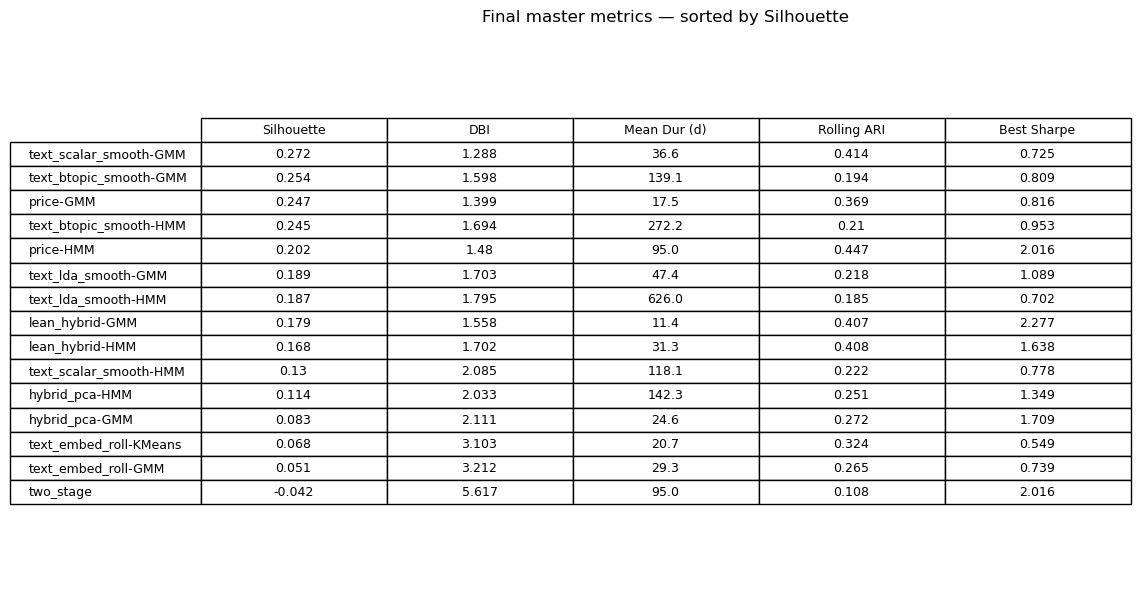

In [26]:
# Save final tables and master-table image for the report
master_by_sil.to_csv(f"{DATA_DIR}/final_metrics.csv")
print(f"Saved: {DATA_DIR}/final_metrics.csv")

inv_rows = []
for name, series in all_regimes.items():
    s = series.dropna()
    inv_rows.append({
        "pipeline":  name,
        "n_days":    len(s),
        "date_min":  s.index.min().date() if len(s) else None,
        "date_max":  s.index.max().date() if len(s) else None,
        "n_regimes": int(s.max()) + 1 if len(s) else 0,
    })
inv = pd.DataFrame(inv_rows)
inv.to_csv(f"{DATA_DIR}/final_pipeline_inventory.csv", index=False)
print(f"Saved: {DATA_DIR}/final_pipeline_inventory.csv")
display(inv)

fig, ax = plt.subplots(figsize=(12, 0.42 * len(master_by_sil) + 1))
ax.axis("off")
tbl = ax.table(
    cellText=master_by_sil.round(3).values,
    rowLabels=master_by_sil.index,
    colLabels=master_by_sil.columns,
    cellLoc="center",
    loc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.45)
plt.title("Final master metrics — sorted by Silhouette")
plt.savefig(f"{IMAGES_DIR}/final_master_table.png", dpi=140, bbox_inches="tight")
plt.show()
